# Сравнение ответов 2–3 submissions
Выберите CSV в SUBMISSIONS, затем выполните ячейки. Сопоставление **по ID**,
а не по порядку строк. Показываются только картинки, где хотя бы две модели
предсказали разные метки, с ответами всех выбранных моделей.

Никакие веса или probabilities не нужны. Данные/CSV не изменяются,
обучение и inference не запускаются. Истинные метки test неизвестны —
это просмотр расхождений, а не определение ошибок модели.


In [1]:
from pathlib import Path
from itertools import combinations
import math
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':
    ROOT=ROOT.parent
if not (ROOT/'submissions').is_dir():
    raise RuntimeError('Укажите ROOT — корень проекта с submissions/')

SUBMISSIONS={
    # 'AGMFA train': ROOT/'submissions/submission_agmfa_hardshift_train.csv',
    'AGMFA train+val': ROOT/'submissions/submission_agmfa_hardshift_train_val.csv',
    # Для сравнения трёх моделей раскомментируйте или замените путь:
    'ResNet101': ROOT/'submissions/submissions_001_resnet101_train_val.csv',
    'ResNet ensemble': ROOT/'submissions/submissions_001_ensemble_train_val.csv',
}
TEST_DIR=ROOT/'data/raw/test'
CLASSES_CSV=ROOT/'data/raw/classes.csv'

START=0          # Следующая страница: 24, 48, 72, ...
PAGE_SIZE=50     # Сколько небольших картинок показывать за один запуск
COLUMNS=4
RANDOM_ORDER=False
SEED=42
FILTER_CLASS=None  # Необязательно: class_name либо label; любой ответ модели


In [2]:
def compare_submissions(submissions, classes_csv):
    if len(submissions) not in (2,3):
        raise ValueError('Выберите ровно 2 или 3 submissions')
    if 'id' in submissions:
        raise ValueError('Имя модели не должно быть id')
    classes=pd.read_csv(classes_csv,dtype={'label':str})
    if not {'label','class_name'}.issubset(classes.columns) or classes.label.isna().any() or classes.label.duplicated().any():
        raise ValueError('classes.csv требует уникальные label и class_name')
    names=classes.set_index('label').class_name.to_dict()
    frames={}
    for model,path in submissions.items():
        data=pd.read_csv(path,dtype={'id':str,'label':str})
        if list(data.columns)!=['id','label']:
            raise ValueError(f'{model}: ожидаются колонки id,label')
        if data.empty or data.isna().any().any() or data.id.eq('').any() or data.id.duplicated().any():
            raise ValueError(f'{model}: пустые/повторяющиеся IDs либо пустые labels')
        if not data.label.isin(names).all():
            raise ValueError(f'{model}: labels отсутствуют в classes.csv')
        frames[model]=data.set_index('id')['label']
    models=list(submissions)
    first=frames[models[0]]
    merged=pd.DataFrame(index=first.index)
    for model,values in frames.items():
        missing=set(first.index)-set(values.index)
        extra=set(values.index)-set(first.index)
        if missing or extra:
            raise ValueError(f'{model}: ID sets различаются; missing={len(missing)}, extra={len(extra)}')
        merged[model]=values.reindex(first.index)
    merged=merged.reset_index()
    different=merged[models].nunique(axis=1)>1
    disagreements=merged.loc[different].copy()
    pair_rows=[]
    for a,b in combinations(models,2):
        count=int(merged[a].ne(merged[b]).sum())
        pair_rows.append({'model_A':a,'model_B':b,'different':count,'different_pct':100*count/len(merged)})
    return merged,disagreements,names,pd.DataFrame(pair_rows)

all_answers,disagreements,class_names,pair_counts=compare_submissions(SUBMISSIONS,CLASSES_CSV)
models=list(SUBMISSIONS)
print(f'Всего объектов: {len(all_answers)}; расхождения: {len(disagreements)} ({len(disagreements)/len(all_answers):.2%})')
display(pair_counts)
if len(models)==3:
    print('Все три ответа различаются:',int((disagreements[models].nunique(axis=1)==3).sum()))


Всего объектов: 8299; расхождения: 393 (4.74%)
Все три ответа различаются: 11


,model_A,model_B,different,different_pct
0,AGMFA train+val,ResNet101,364,4.386071
1,AGMFA train+val,ResNet ensemble,291,3.506447
2,ResNet101,ResNet ensemble,142,1.711050


Следующая страница: START = 50


,id,AGMFA train+val,ResNet101,ResNet ensemble
0,20.jpg,palace (9),church (3),church (3)
1,35.jpg,baseball_diamond (0),rectangular_farmland (12),rectangular_farmland (12)
2,331.jpg,palace (9),church (3),church (3)
3,339.jpg,bridge (2),overpass (8),overpass (8)
4,346.jpg,bridge (2),commercial_area (5),commercial_area (5)
5,372.jpg,commercial_area (5),wetland (19),wetland (19)
6,457.jpg,sea_ice (15),snowberg (16),sea_ice (15)
7,469.jpg,palace (9),basketball_court (1),basketball_court (1)
8,477.jpg,palace (9),church (3),church (3)
9,494.jpg,lake (6),wetland (19),lake (6)


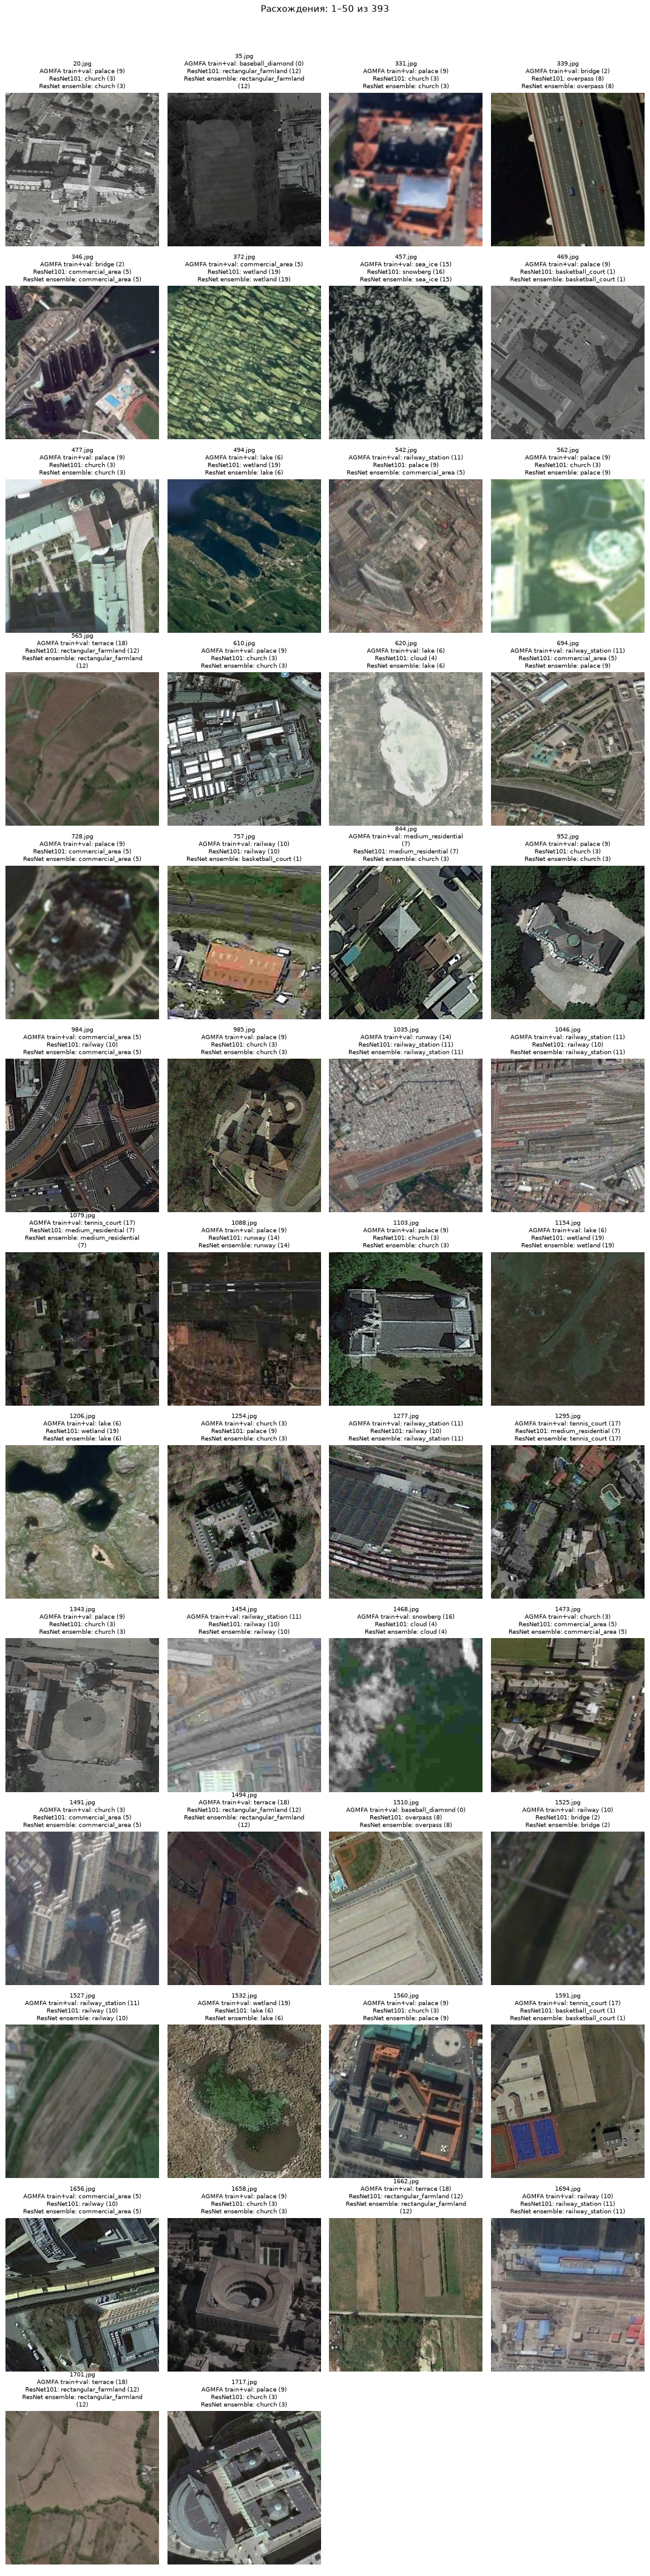

In [3]:
def show_disagreements(disagreements, models, class_names, image_dir, *, start=0, page_size=24,
                       columns=4, random_order=False, seed=42, filter_class=None):
    if start<0 or page_size<1 or columns<1:
        raise ValueError('START>=0, PAGE_SIZE>=1, COLUMNS>=1')
    selected=disagreements.copy()
    if filter_class is not None:
        value=str(filter_class)
        labels=[label for label,name in class_names.items() if label==value or name==value]
        if not labels:
            raise ValueError(f'Неизвестный класс: {filter_class}')
        selected=selected[selected[models].isin(labels).any(axis=1)]
    if random_order:
        selected=selected.sample(frac=1,random_state=seed)
    page=selected.iloc[start:start+page_size]
    if page.empty:
        print(f'На этой странице нет объектов. После фильтра: {len(selected)}; START={start}')
        return None
    table=page.copy()
    for model in models:
        table[model]=table[model].map(lambda label: f'{class_names[label]} ({label})')
    display(table.reset_index(drop=True))
    directory=Path(image_dir).resolve()
    fig,axes=plt.subplots(math.ceil(len(page)/columns),columns,
                          figsize=(columns*3,math.ceil(len(page)/columns)*3.7),squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax,(_,row) in zip(axes.flat,page.iterrows()):
        path=(directory/row['id']).resolve()
        if not path.is_relative_to(directory):
            raise ValueError('Image ID выходит за пределы TEST_DIR')
        with Image.open(path) as image:
            ax.imshow(image.convert('RGB'))
        caption=[row['id']]
        for model in models:
            caption.extend(textwrap.wrap(f'{model}: {class_names[row[model]]} ({row[model]})',width=38))
        ax.set_title('\n'.join(caption),fontsize=8)
    fig.suptitle(f'Расхождения: {start+1}–{start+len(page)} из {len(selected)}',fontsize=12)
    fig.tight_layout(rect=(0,0,1,.97))
    plt.show()
    plt.close(fig)
    print(f'Следующая страница: START = {start+page_size}')
    return fig

fig=show_disagreements(disagreements,models,class_names,TEST_DIR,
    start=START,page_size=PAGE_SIZE,columns=COLUMNS,random_order=RANDOM_ORDER,
    seed=SEED,filter_class=FILTER_CLASS)
